# Research Papers: Trend Mining AI

Importing necessary libraries.

In [ ]:
!pip install -q pyLDAvis
import pyLDAvis
import re
import unicodedata
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import time
import matplotlib.pyplot as plt
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import chi2
from nltk.stem import PorterStemmer
from scipy import stats
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    PrecisionRecallDisplay,
    RocCurveDisplay,
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)

from sklearn.model_selection import(
    StratifiedKFold,
    cross_validate,
    learning_curve,
    train_test_split,
    RepeatedStratifiedKFold,
    cross_val_score,
)

from scipy.stats import wilcoxon
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer


DATA_PATH = "/content/research_abstracts.json"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

print("Python environment ready.")

Python environment ready.


 ## 1.Corpus Dataframe.

-Load the data and denoise the text.
- Load and audit the  raw data.
- Remove the structural noise( missing rows and duplicates)
- remove textual noise( boiler-plate, URLs, LaTex and copyright lines, punctuation and stopwords)
- Normalise ( lower case and stemming)

In [ ]:
df_raw = pd.read_json(DATA_PATH)
print("Shape:", df_raw.shape)
print("Column types:\n",df_raw.dtypes)
print("\nMissing Values:\n",df_raw.isna().sum())
print("\nDuplicated Rows:\n",df_raw["Abstract"].duplicated().sum())

label_col = "Labels" if "Labels" in df_raw.columns else "Label"
print("\nClass balance:\n", df_raw[label_col].value_counts())
print("\nClass balance(%)\n", (df_raw[label_col].value_counts(normalize=True) * 100).round(1))
print("\nMissing DOIs:\n", df_raw["DOI"].isna().sum() if "DOI" in df_raw.columns else "DOI column not found")
df_raw.head()

noise_audit = {
    "URLs / web addresses": r"https?://\S+|www\.\S+",
    "LaTeX / $...$ maths": r"\$[^$]*\$",
    "Copyright / (c) notices": r"©|copyright|all rights reserved",
    "Leading 'Abstract'/'Summary' label": r"^\s*(?:abstract|summary)\b",
    "Non-ASCII characters (curly quotes, dashes...)": r"[^\x00-\x7f]",
    "Digits": r"\d",
    "Runs of 2+ whitespace": r"\s{2,}",
}
audit = pd.Series(
    {k: int(df_raw["Abstract"].str.contains(p, case=False, regex=True).sum())
     for k, p in noise_audit.items()}
)
print("\nNumber of abstracts containing each type of noise:\n", audit)

df = df_raw.copy()
n0 = len(df)

df = df.dropna(subset=["Abstract", label_col])
df["Abstract"] = df["Abstract"].astype(str).str.strip()
df = df[df["Abstract"].str.len() > 0]

# Removing the duplicates to prevent any data leaks.
dup_label_conflicts = df.groupby("Abstract")[label_col].nunique().gt(1).sum()
print(f"Duplicate abstracts with conflicting labels: {dup_label_conflicts}")
df = df.drop_duplicates(subset="Abstract", keep="first").reset_index(drop=True)
print(f"Rows: {n0} -> {len(df)} (removed {n0 - len(df)} duplicate/empty rows)")

# Removing textual noise.
stemmer = PorterStemmer()
STOP_WORDS = set(ENGLISH_STOP_WORDS)
# Words that appear in  *every* abstract and carry no important/detailed information
DOMAIN_STOP = {"paper", "study", "article", "results", "result", "show", "shows",
               "use", "using", "used", "propose", "proposed", "based", "approach"}
STOP_WORDS |= DOMAIN_STOP

_STEM_CACHE = {}


def stem(word: str) -> str:
    if word not in _STEM_CACHE:
        _STEM_CACHE[word] = stemmer.stem(word)
    return _STEM_CACHE[word]


def denoise(text: str) -> str:
    """Return a cleaned, lower-cased, stop-word-free, stemmed version of `text`."""

    # 1. Unicode normalisation: curly quotes/ligatures -> plain forms; fancy hyphens -> '-'
    text = unicodedata.normalize("NFKC", text)
    text = re.sub(r"[‐-―−]", "-", text)
    # 2. Boiler-plate label at the very start ("Abstract", "Summary")
    text = re.sub(r"^\s*(?:abstract|summary)\s*[:.\-]?\s*", " ", text, flags=re.I)
    # 3. URLs, DOIs, e-mail addresses
    text = re.sub(r"https?://\S+|www\.\S+|\S+@\S+\.\S+|doi:\s*\S+", " ", text, flags=re.I)
    # 4. LaTeX / inline maths such as $f(R)$ and $\sqrt{T}$
    text = re.sub(r"\$[^$]*\$", " ", text)
    # 5. Publisher copyright notices ("Copyright (c) 2008 John Wiley & Sons, Ltd.")
    text = re.sub(r"(?:copyright\s*)?©[^.]*?(?:ltd|b\.v|inc|elsevier|wiley|springer)[^.]*\.?",
                  " ", text, flags=re.I)
    text = re.sub(r"all rights reserved\.?", " ", text, flags=re.I)
    # 6. Lower-case
    text = text.lower()
    # 7. Keep letters only (drops digits, punctuation, symbols); hyphens split words
    text = re.sub(r"[^a-z\s]", " ", text)
    # 8. Tokenise, drop short tokens + stop-words, stem
    tokens = [stem(t) for t in text.split() if len(t) > 2 and t not in STOP_WORDS]
    return " ".join(tokens)


# Show what the cleaner does on a handful of examples
example_idx = df.index[df["Abstract"].str.contains(r"Copyright|\$|https?://", regex=True)][:2].tolist() + [0]
for i in example_idx:
    print("-" * 100)
    raw_i, clean_i = df.loc[i, "Abstract"].replace("\n", " "), denoise(df.loc[i, "Abstract"])
    print("RAW   : ...", raw_i[-200:])      # tail shows copyright notices / URLs
    print("CLEAN : ...", clean_i[-200:])

# Normalise ( lower case and stemming)
df["clean_text"] = df["Abstract"].apply(denoise)

# Drop anything that became (almost) empty after cleaning
df["n_tokens"] = df["clean_text"].str.split().str.len()
print("\nToken count after cleaning:\n", df["n_tokens"].describe().round(1))
df = df[df["n_tokens"] >= 5].reset_index(drop=True)

# Sanity checks that the noise really is gone
leftovers = {
    "URL": r"http|www",
    "copyright": r"copyright|©",
    "digits": r"\d",
    "non-ascii": r"[^\x00-\x7f]",
    "dollar": r"\$",
}
print("\nResidual noise (should all be 0):",
      {k: int(df["clean_text"].str.contains(p, regex=True).sum()) for k, p in leftovers.items()})

# Vocabulary size before vs after
raw_vocab = set(w for t in df["Abstract"].str.lower() for w in t.split())
clean_vocab = set(w for t in df["clean_text"] for w in t.split())
print(f"Vocabulary size: raw {len(raw_vocab):,} -> cleaned {len(clean_vocab):,} "
      f"({(1 - len(clean_vocab) / len(raw_vocab)) * 100:.0f}% smaller)")
print("Final modelling dataset:", df.shape)

Shape: (1138, 3)
Column types:
 DOI         object
Abstract    object
Label       object
dtype: object

Missing Values:
 DOI         4
Abstract    0
Label       0
dtype: int64

Duplicated Rows:
 13

Class balance:
 Label
classical    900
ai           238
Name: count, dtype: int64

Class balance(%)
 Label
classical    79.1
ai           20.9
Name: proportion, dtype: float64

Missing DOIs:
 4

Number of abstracts containing each type of noise:
 URLs / web addresses                                7
LaTeX / $...$ maths                                18
Copyright / (c) notices                            16
Leading 'Abstract'/'Summary' label                 38
Non-ASCII characters (curly quotes, dashes...)    443
Digits                                            689
Runs of 2+ whitespace                              46
dtype: int64
Duplicate abstracts with conflicting labels: 0
Rows: 1138 -> 1125 (removed 13 duplicate/empty rows)
---------------------------------------------------------------

1.2 Identify relevant columns: feature modelling


Train size: (900, 6)
Test size: (225, 6)
Train share of ai: 0.209
Test share of ai: 0.209
           dtype  n_unique  n_missing  pct_unique  \
DOI       object      1134          4        99.6   
Abstract  object      1125          0        98.9   
Label     object         2          0         0.2   

                                      role  
DOI               identifier (near-unique)  
Abstract  free text -> main feature source  
Label                               target  
Label       ai  classical
doi_prefix               
10.1002      1         24
10.1007     18         41
10.1016     22        124
10.1080      2         41
10.1109     37          7
10.1111      2         37
10.2139     26        217
10.48550    21          6
other       59        215

DOI prefix vs Label: chi2=197.9, dof=8, p=1.77e-38, Cramer's V=0.47

Full DOI strings are unique per paper (1134 unique of 1138), so they cannot generalise to unseen papers.
The prefix is associated with Label, but it identifies 

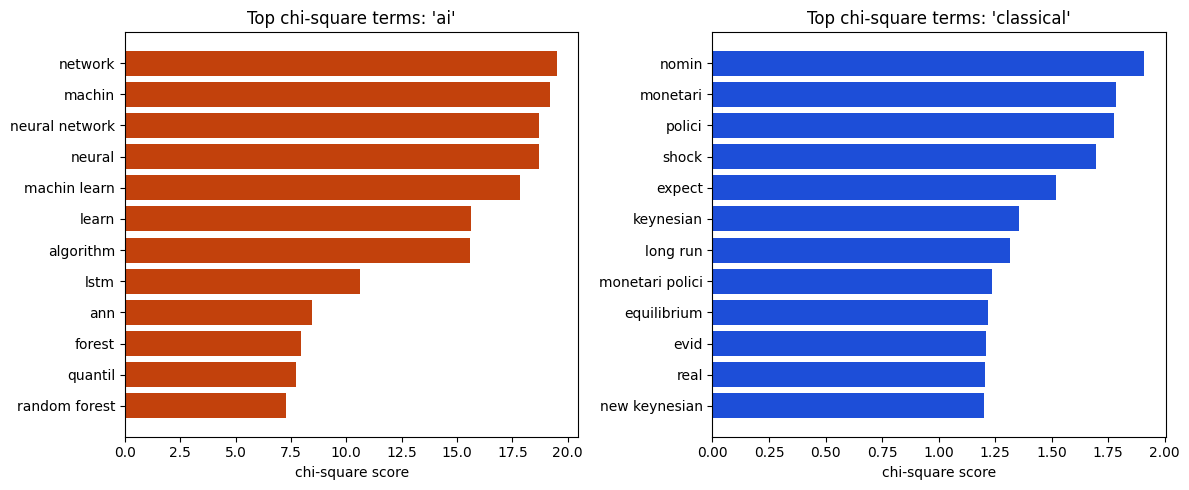

In [ ]:
# Turn the text labels into numbers: classical = 0, ai = 1
df["y"] = df["Label"].map({"classical": 0, "ai": 1})

# Split into 80% train / 20% test, keeping the same class balance in both
train_df, test_df = train_test_split(
    df, test_size=0.2, stratify=df["y"], random_state=42
)

print("Train size:", train_df.shape)
print("Test size:", test_df.shape)

print("Train share of ai:", round(train_df["y"].mean(), 3))
print("Test share of ai:", round(test_df["y"].mean(), 3))

n_unique = df_raw.nunique()

col_audit = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": n_unique,
    "n_missing": df_raw.isna().sum(),
    "pct_unique": (n_unique / len(df_raw) * 100).round(1),
})

col_audit["role"] = [
    "identifier (near-unique)",
    "free text -> main feature source",
    "target",
 ]

print(col_audit)

def doi_prefix(doi):
    """Return the publisher part of a DOI."""
    if pd.isna(doi):
        return "missing"
    match = re.search(r"10\.\d+", doi)
    return match.group(0) if match else "url/other"

train_df = train_df.assign(doi_prefix=train_df["DOI"].apply(doi_prefix))
top_prefixes = train_df["doi_prefix"].value_counts().head(8).index
grouped = train_df["doi_prefix"].where(train_df["doi_prefix"].isin(top_prefixes), "other")
ct = pd.crosstab(grouped, train_df["Label"])
chi2_stat, p_val, dof, _ = stats.chi2_contingency(ct)
n = ct.values.sum()
cramers_v = np.sqrt(chi2_stat / (n * (min(ct.shape) - 1)))

print(ct)
print(f"\nDOI prefix vs Label: chi2={chi2_stat:.1f}, dof={dof}, p={p_val:.2e}, Cramer's V={cramers_v:.2f}")

print(f"\nFull DOI strings are unique per paper ({df_raw['DOI'].nunique()} unique of {len(df_raw)}), "
      "so they cannot generalise to unseen papers.")
print("The prefix is associated with Label, but it identifies the publisher/repository "
      "(e.g. arXiv, IEEE, SSRN), not the paper's content, so it is a shortcut feature "
      "and is excluded from the semantic baseline.")

# Work out the pieces once and reuse them
abstract = train_df["Abstract"]
n_words = abstract.str.split().str.len()
n_letters = abstract.str.replace(r"\s+", "", regex=True).str.len()  # characters without spaces

# Add the length features
train_df = train_df.assign(
    n_chars=abstract.str.len(),
    n_words=n_words,
    avg_word_len=n_letters / n_words,
    n_tokens_clean=train_df["n_tokens"],
)

# Split the data by class
ai = train_df[train_df["y" ] == 1]
classical = train_df[train_df["y"] == 0]

# Compare each feature between the two classes
results = []
for col in ["n_chars", "n_words", "avg_word_len", "n_tokens_clean"]:
    a = ai[col]
    b = classical[col]

    # Mann-Whitney U test: do the two distributions differ?
    u, p = stats.mannwhitneyu(a, b)

    # Rank-biserial correlation: effect size from -1 to 1
    effect = 1 - 2 * u / (len(a) * len(b))

    results.append({
        "feature": col,
        "median_ai": a.median(),
        "median_classical": b.median(),
        "p_value": p,
        "|rank_biserial|": abs(effect),
    })

length_tests = pd.DataFrame(results).round(4)
print(length_tests)

tfidf_explore = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.9,
    sublinear_tf=True,
)

X_tr_explore = tfidf_explore.fit_transform(train_df["clean_text"])

chi_scores, chi_p = chi2(X_tr_explore, train_df["y"])

terms = np.array(tfidf_explore.get_feature_names_out())

y = train_df["y"].values

# Average TF-IDF score of every term within each class
mean_ai = np.asarray(X_tr_explore[y == 1].mean(axis=0)).ravel()
mean_classical = np.asarray(X_tr_explore[y == 0].mean(axis=0)).ravel()

# One row per term: its chi-square score, p-value, and which class uses it more
term_table = pd.DataFrame({
    "term": terms,
    "chi2": chi_scores,
    "p": chi_p,
    "favours": np.where(mean_ai > mean_classical, "ai", "classical"),
})
term_table = term_table.sort_values("chi2", ascending=False)

# Separate the terms by class, strongest first
ai_terms = term_table[term_table["favours"] == "ai"]
classical_terms = term_table[term_table["favours"] == "classical"]

print("Vocabulary kept (min_df=3, uni+bi-grams):", len(terms))
print("Significant terms at p<0.05:", int((term_table["p"] < 0.05).sum()))

print("\nTop 15 terms for 'ai':")
print(ai_terms.head(15)[["term", "chi2"]].to_string(index=False))

print("\nTop 15 terms for 'classical':")
print(classical_terms.head(15)[["term", "chi2"]].to_string(index=False))

# Plot the top 12 terms for each class side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
panels = [
    ("ai", ai_terms, "#C2410C"),
    ("classical", classical_terms, "#1D4ED8"),
]

for ax, (label, class_terms, colour) in zip(axes, panels):
    top = class_terms.head(12).iloc[::-1]  # reversed so the strongest term ends up at the top
    ax.barh(top["term"], top["chi2"], color=colour)
    ax.set_title(f"Top chi-square terms: '{label}'")
    ax.set_xlabel("chi-square score")

plt.tight_layout()
plt.show()

1.3 Baseline model and perormance report.

                Dummy (majority) - test  Baseline - train  Baseline - test
Accuracy                          0.791             0.989            0.880
Balanced acc.                     0.500             0.987            0.822
Precision (ai)                    0.000             0.964            0.708
Recall (ai)                       0.000             0.984            0.723
F1 (ai)                           0.000             0.974            0.716
Macro F1                          0.442             0.983            0.820
ROC-AUC                           0.500             0.999            0.895

Classification report (TEST set):
              precision    recall  f1-score   support

   classical       0.93      0.92      0.92       178
          ai       0.71      0.72      0.72        47

    accuracy                           0.88       225
   macro avg       0.82      0.82      0.82       225
weighted avg       0.88      0.88      0.88       225

Train-test gap in macro-F1: 0.163
5-fo

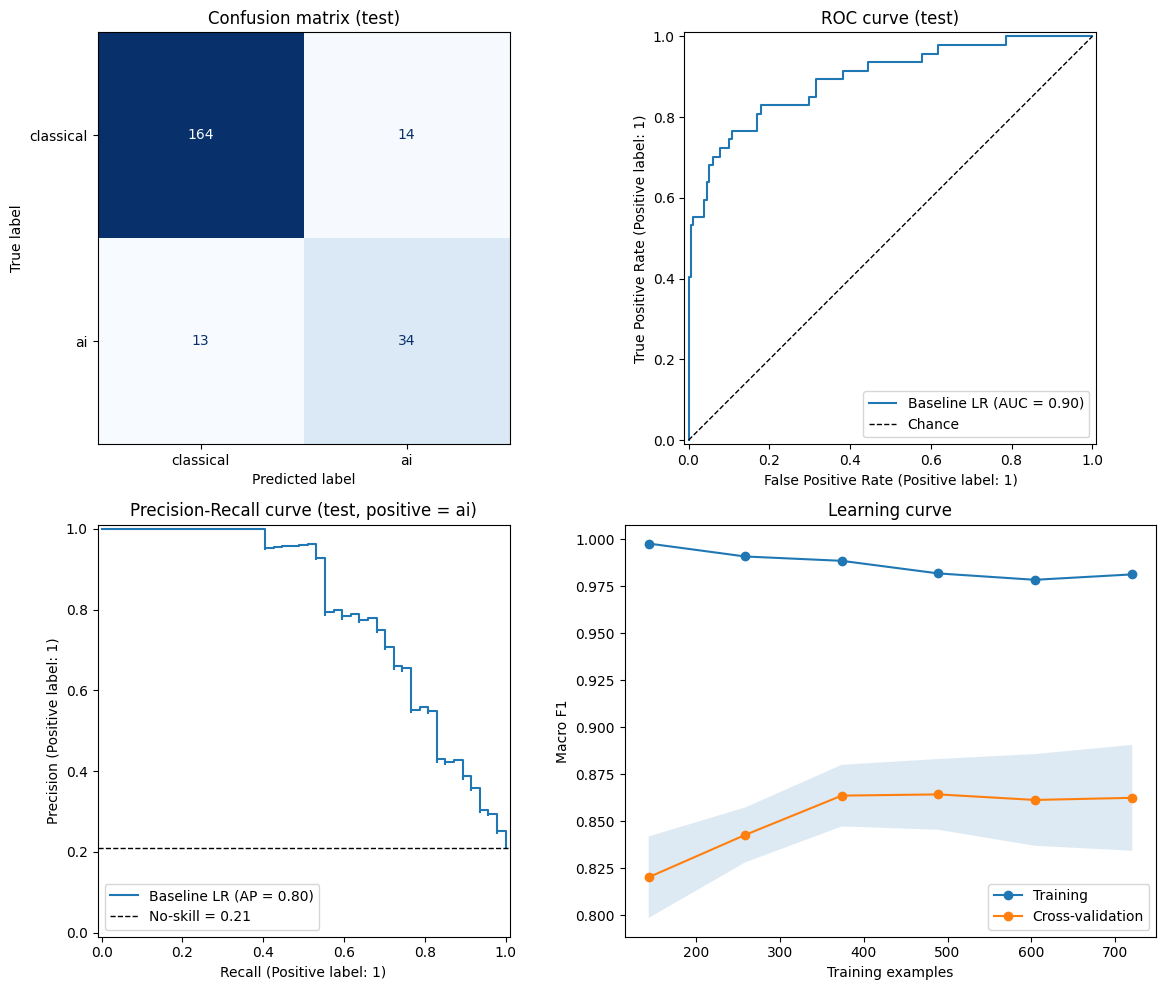

Strongest 'ai' indicators:        network, learn, neural, neural network, machin, algorithm, machin learn, method, quantil, sentiment, lstm, regress
Strongest 'classical' indicators: polici, expect, real, monetari, nomin, evid, rate, suggest, cost, uncertainti, shock, target


In [ ]:
# Define the missing random state
RANDOM_STATE = 42

# Text inputs and labels (0 = classical, 1 = ai)
X_train, y_train = train_df["clean_text"], train_df["y"]
X_test, y_test = test_df["clean_text"], test_df["y"]

# Real model: TF-IDF features -> logistic regression
baseline = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)),
])

# Reference model: always predicts the most common class
dummy = Pipeline([
    ("tfidf", TfidfVectorizer(min_df=3)),
    ("clf", DummyClassifier(strategy="most_frequent")),
])

# Train both on the training set
baseline.fit(X_train, y_train)
dummy.fit(X_train, y_train)

def metrics(model, X, y):
    """Return a dictionary of scores for one model on one dataset, handling classifiers without predict_proba."""
    pred = model.predict(X)

    # Handle models like LinearSVC that don't have predict_proba but have decision_function
    if hasattr(model, "predict_proba"):
        proba = model.predict_proba(X)[:, 1]
    elif hasattr(model, "decision_function"):
        proba = model.decision_function(X)
    else:
        proba = None

    roc_auc = roc_auc_score(y, proba) if proba is not None else np.nan

    return {
        "Accuracy": accuracy_score(y, pred),
        "Balanced acc.": balanced_accuracy_score(y, pred),
        "Precision (ai)": precision_score(y, pred, zero_division=0),
        "Recall (ai)": recall_score(y, pred, zero_division=0),
        "F1 (ai)": f1_score(y, pred, zero_division=0),
        "Macro F1": f1_score(y, pred, average="macro", zero_division=0),
        "ROC-AUC": roc_auc,
    }

# Scores side by side: dummy on test, baseline on train, baseline on test
report = pd.DataFrame({
    "Dummy (majority) - test": metrics(dummy, X_test, y_test),
    "Baseline - train": metrics(baseline, X_train, y_train),
    "Baseline - test": metrics(baseline, X_test, y_test),
}).round(3)

# A model that gives every row the same score can only match chance
report.loc["ROC-AUC", "Dummy (majority) - test"] = 0.5

print(report)

# Per-class breakdown on the test set
print("\nClassification report (TEST set):")
print(classification_report(y_test, baseline.predict(X_test), target_names=["classical", "ai"]))

# A large train-test gap suggests the model is overfitting
gap = report.loc["Macro F1", "Baseline - train"] - report.loc["Macro F1", "Baseline - test"]
print(f"Train-test gap in macro-F1: {gap:.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Metrics to track: short name -> scikit-learn scoring name
scoring = {
    "accuracy": "accuracy",
    "f1_ai": "f1",
    "macro_f1": "f1_macro",
    "roc_auc": "roc_auc",
}

# Train and score the pipeline on each fold
cv_res = cross_validate(
    baseline, X_train, y_train,
    cv=cv, scoring=scoring, return_train_score=True,
)

# Summarise each metric across the 5 folds
rows = {}
for name in scoring:
    rows[name] = {
        "train mean": cv_res[f"train_{name}"].mean(),
        "val mean": cv_res[f"test_{name}"].mean(),
        "val std": cv_res[f"test_{name}"].std(),
    }

cv_table = pd.DataFrame(rows).T.round(3)

print("5-fold stratified CV on the training split:")
print(cv_table)

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
ax_cm, ax_roc, ax_pr, ax_lc = axes.ravel()

# 1. Confusion matrix: correct vs wrong predictions on the test set
ConfusionMatrixDisplay.from_estimator(
    baseline, X_test, y_test,
    display_labels=["classical", "ai"], cmap="Blues", colorbar=False, ax=ax_cm,
)
ax_cm.set_title("Confusion matrix (test)")
ax_cm.grid(False)

# 2. ROC curve: the dashed diagonal is a model guessing at random
RocCurveDisplay.from_estimator(baseline, X_test, y_test, name="Baseline LR", ax=ax_roc)
ax_roc.plot([0, 1], [0, 1], "k--", lw=1, label="Chance")
ax_roc.set_title("ROC curve (test)")
ax_roc.legend()

# 3. Precision-recall curve: the dashed line is the share of "ai" rows
no_skill = y_test.mean()
PrecisionRecallDisplay.from_estimator(baseline, X_test, y_test, name="Baseline LR", ax=ax_pr)
ax_pr.axhline(no_skill, color="k", ls="--", lw=1, label=f"No-skill = {no_skill:.2f}")
ax_pr.set_title("Precision-Recall curve (test, positive = ai)")
ax_pr.legend()

# 4. Learning curve: score vs amount of training data
sizes, train_scores, val_scores = learning_curve(
    baseline, X_train, y_train, cv=cv, scoring="f1_macro",
    train_sizes=np.linspace(0.2, 1.0, 6), n_jobs=-1,
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

ax_lc.plot(sizes, train_mean, "o-", label="Training")
ax_lc.plot(sizes, val_mean, "o-", label="Cross-validation")
ax_lc.fill_between(sizes, val_mean - val_std, val_mean + val_std, alpha=0.15)
ax_lc.set_xlabel("Training examples")
ax_lc.set_ylabel("Macro F1")
ax_lc.set_title("Learning curve")
ax_lc.legend()

plt.tight_layout()
plt.show()

tfidf = baseline.named_steps["tfidf"]
clf = baseline.named_steps["clf"]

coefs = clf.coef_[0]
vocab = np.array(tfidf.get_feature_names_out())

# Sort terms from lowest weight (classical) to highest weight (ai)
order = np.argsort(coefs)
top_classical = vocab[order[:12]]
top_ai = vocab[order[-12:][::-1]]

print("Strongest 'ai' indicators:       ", ", ".join(top_ai))
print("Strongest 'classical' indicators:", ", ".join(top_classical))

## 2. Preprocessing denoising

2.1 Train at least four models and compare with the baseline.

  Models used to train:
-  Logistic Regression
-  Linear SVM
- Complement Naive Bayes
- Random Forest
- Gradient Boosting

                                CV macro-F1  CV std  CV F1 (ai)  CV ROC-AUC  \
Model                                                                         
Linear SVM                            0.889   0.025       0.818       0.940   
Complement Naive Bayes                0.867   0.023       0.788       0.933   
Logistic Regression (baseline)        0.862   0.028       0.780       0.933   
Gradient Boosting                     0.854   0.029       0.760       0.900   
Random Forest                         0.824   0.038       0.704       0.922   

                                Test macro-F1  Test F1 (ai)  Test recall (ai)  \
Model                                                                           
Linear SVM                              0.815         0.699             0.617   
Complement Naive Bayes                  0.823         0.722             0.745   
Logistic Regression (baseline)          0.820         0.716             0.723   
Gradient Boosting                       0

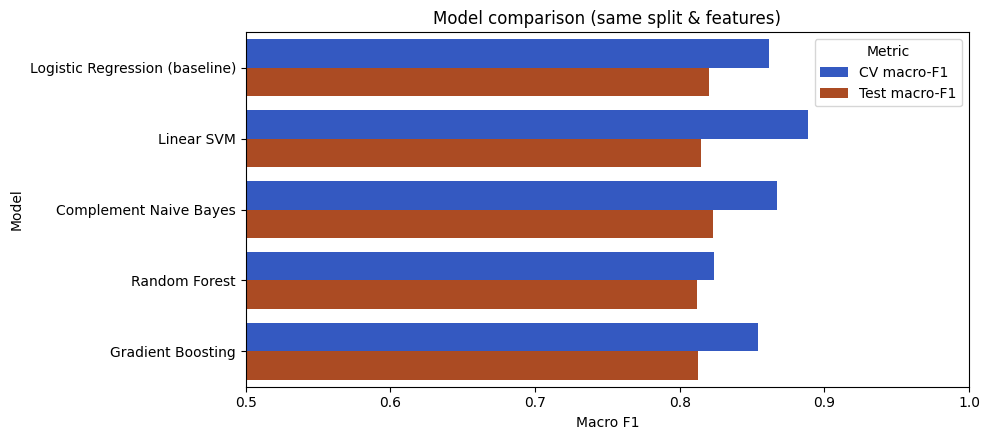

In [ ]:
def make_tfidf():
    return TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True)

# Models to compare
candidates = {
    "Logistic Regression (baseline)": LogisticRegression(
        class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE),
    "Linear SVM": LinearSVC(class_weight="balanced", random_state=RANDOM_STATE),
    "Complement Naive Bayes": ComplementNB(alpha=0.3),
    "Random Forest": RandomForestClassifier(
        n_estimators=400, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=200, learning_rate=0.1, max_depth=3,
        subsample=0.8, random_state=RANDOM_STATE),
}

results = []
fitted = {}

for name, model in candidates.items():
    start = time.time()
    pipe = Pipeline([("tfidf", make_tfidf()), ("clf", clone(model))])

    # 5-fold cross-validation on the training data
    cv_res = cross_validate(
        pipe, X_train, y_train, cv=cv,
        scoring={"f1_macro": "f1_macro", "f1_ai": "f1", "roc_auc": "roc_auc"},
    )

    # Fit on the full training set, then score once on the test set
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    test = metrics(pipe, X_test, y_test)

    results.append({
        "Model": name,
        "CV macro-F1": cv_res["test_f1_macro"].mean(),
        "CV std": cv_res["test_f1_macro"].std(),
        "CV F1 (ai)": cv_res["test_f1_ai"].mean(),
        "CV ROC-AUC": cv_res["test_roc_auc"].mean(),
        "Test macro-F1": test["Macro F1"],
        "Test F1 (ai)": test["F1 (ai)"],
        "Test recall (ai)": test["Recall (ai)"],
        "Test ROC-AUC": test["ROC-AUC"],
        "Test acc.": test["Accuracy"],
        "Seconds": time.time() - start,
    })

comparison = pd.DataFrame(results).set_index("Model").round(3)
print(comparison.sort_values("CV macro-F1", ascending=False))

# Pick the winner using cross-validation, not the test set
best_name = comparison["CV macro-F1"].idxmax()
print(f"\nBest model by cross-validation: {best_name}")

# Bar chart: cross-validation vs test macro-F1 for each model
plot_df = comparison[["CV macro-F1", "Test macro-F1"]].reset_index().melt("Model", var_name="Metric")

plt.figure(figsize=(10, 4.5))
sns.barplot(data=plot_df, y="Model", x="value", hue="Metric", palette=["#1D4ED8", "#C2410C"])
plt.xlim(0.5, 1.0)
plt.xlabel("Macro F1")
plt.title("Model comparison (same split & features)")
plt.tight_layout()
plt.show()

2.2 Predictive performance enhancement

Best parameters: {'clf__C': 0.5, 'tfidf__max_df': 0.8, 'tfidf__min_df': 5, 'tfidf__ngram_range': (1, 2)}
Repeated-CV macro-F1 (15 folds): baseline 0.859 | Linear SVM default 0.885 | tuned 0.890
                Q1 baseline (LR)  Linear SVM (default)  Linear SVM (tuned)
Accuracy                   0.880                 0.889               0.880
Balanced acc.              0.822                 0.789               0.799
Precision (ai)             0.708                 0.806               0.738
Recall (ai)                0.723                 0.617               0.660
F1 (ai)                    0.716                 0.699               0.697
Macro F1                   0.820                 0.815               0.811
ROC-AUC                    0.895                 0.899               0.891

Classification report - tuned model (TEST):
              precision    recall  f1-score   support

   classical       0.91      0.94      0.93       178
          ai       0.74      0.66      0.70        4

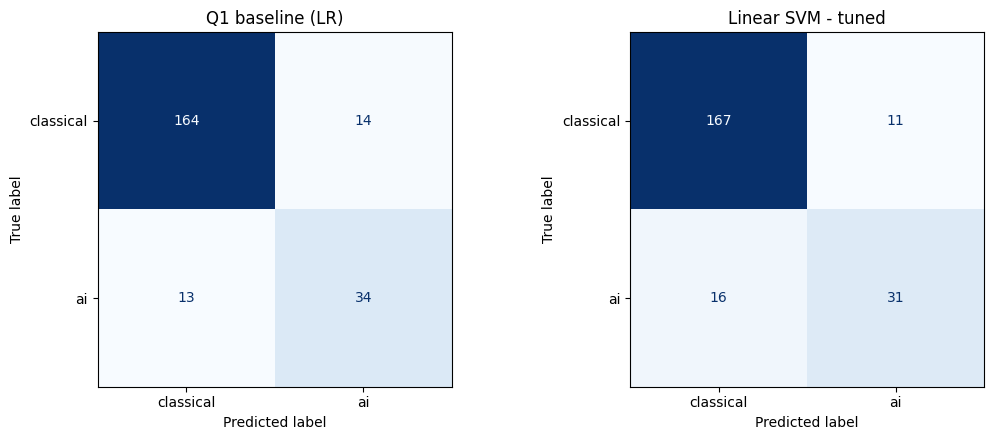

In [ ]:
from sklearn.model_selection import GridSearchCV
# Names used several times below
lr_model = fitted["Logistic Regression (baseline)"]
default_model = fitted[best_name]
best_estimator = candidates[best_name]

# Pipeline to tune: TF-IDF followed by the best model
base_pipe = Pipeline([("tfidf", make_tfidf()), ("clf", clone(best_estimator))])

# Settings to try
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [2, 3, 5],
    "tfidf__max_df": [0.8, 0.9],
}
if hasattr(best_estimator, "C"):
    param_grid["clf__C"] = [0.1, 0.3, 0.5, 1, 2]
elif hasattr(best_estimator, "alpha"):
    param_grid["clf__alpha"] = [0.03, 0.1, 0.3, 1.0]

# 5-fold CV repeated 3 times (15 folds), on the training data only
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

grid = GridSearchCV(base_pipe, param_grid, scoring="f1_macro", cv=rcv, n_jobs=-1)
grid.fit(X_train, y_train)
tuned = grid.best_estimator_
print("Best parameters:", grid.best_params_)

# Macro-F1 for each fold (cross_val_score trains a fresh copy of the model)
def cv_macro_f1(model, X, y, cv):
    return cross_val_score(model, X, y, cv=cv, scoring="f1_macro", n_jobs=-1)

# Like-for-like comparison on the SAME folds (training data only)
cv_base = cv_macro_f1(lr_model, X_train, y_train, rcv)
cv_default = cv_macro_f1(default_model, X_train, y_train, rcv)
cv_tuned = cv_macro_f1(tuned, X_train, y_train, rcv)

print(f"Repeated-CV macro-F1 (15 folds): baseline {cv_base.mean():.3f} | "
      f"{best_name} default {cv_default.mean():.3f} | tuned {cv_tuned.mean():.3f}")

# Before vs after (and vs the Q1 baseline) on the untouched test set

name_base = "Q1 baseline (LR)"
name_default = f"{best_name} (default)"
name_tuned = f"{best_name} (tuned)"

before_after = pd.DataFrame({
    name_base: metrics(lr_model, X_test, y_test),
    name_default: metrics(default_model, X_test, y_test),
    name_tuned: metrics(tuned, X_test, y_test),
}).round(3)
print(before_after)

print("\nClassification report - tuned model (TEST):")
print(classification_report(y_test, tuned.predict(X_test), target_names=["classical", "ai"]))

# Confusion matrices: baseline vs tuned
panels = [
    ("Q1 baseline (LR)", lr_model),
    (f"{best_name} - tuned", tuned),
]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, (title, model) in zip(axes, panels):
    ConfusionMatrixDisplay.from_estimator(
        model, X_test, y_test,
        display_labels=["classical", "ai"], cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
    ax.grid(False)

plt.tight_layout()
plt.show()

                      mean macro-F1    std
Q1 baseline (LR)              0.846  0.025
Linear SVM (default)          0.865  0.028
Linear SVM (tuned)            0.864  0.025
Linear SVM default beats baseline in 18/25 folds (mean gain +0.019, Wilcoxon p = 0.0002)
Linear SVM tuned beats baseline in 20/25 folds (mean gain +0.018, Wilcoxon p = 0.0004)


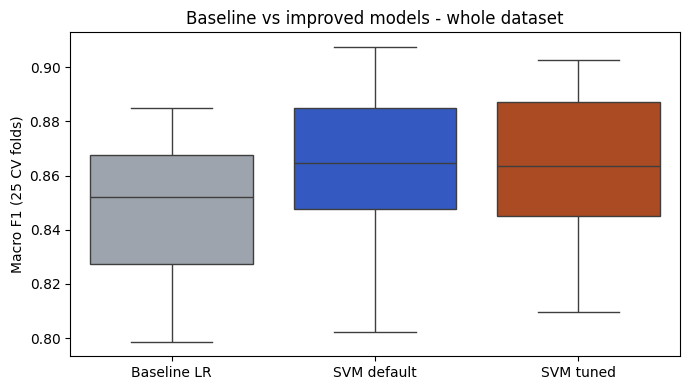

In [ ]:
# Robust check: paired comparison on ALL data (25 folds)
# A single 225-paper test set contains only 47 `ai` papers, so its score moves by +-0.03
# from one split to the next. Repeated CV over the whole dataset gives a steadier verdict.
# (Caveat: the tuned settings were chosen on the training part of this data, so the tuned
# column is slightly optimistic; the untuned SVM column is not affected by that.)

# 5-fold CV repeated 5 times (25 folds); all three models see identical folds
rcv_all = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)
X_all, y_all = df["clean_text"], df["y"]

all_base = cv_macro_f1(lr_model, X_all, y_all, rcv_all)
all_default = cv_macro_f1(default_model, X_all, y_all, rcv_all)
all_tuned = cv_macro_f1(tuned, X_all, y_all, rcv_all)

# Mean and spread of the 25 fold scores for each model
all_scores = {name_base: all_base, name_default: all_default, name_tuned: all_tuned}

rows = {}
for name, fold_scores in all_scores.items():
    rows[name] = {"mean macro-F1": fold_scores.mean(), "std": fold_scores.std()}

robust = pd.DataFrame(rows).T.round(3)
print(robust)

# Does each model beat the baseline? Paired test on the same folds
for label, model_scores in [("default", all_default), ("tuned", all_tuned)]:
    p_value = wilcoxon(model_scores, all_base, alternative="greater").pvalue
    wins = (model_scores > all_base).sum()
    mean_gain = np.mean(model_scores - all_base)
    print(f"{best_name} {label} beats baseline in {wins}/{len(all_base)} folds "
          f"(mean gain {mean_gain:+.3f}, Wilcoxon p = {p_value:.4f})")

# Box plot of the 25 fold scores per model
plt.figure(figsize=(7, 4))
sns.boxplot(
    data=pd.DataFrame({
        "Baseline LR": all_base,
        "SVM default": all_default,
        "SVM tuned": all_tuned,
    }),
    palette=["#9CA3AF", "#1D4ED8", "#C2410C"],
)
plt.ylabel("Macro F1 (25 CV folds)")
plt.title("Baseline vs improved models - whole dataset")
plt.tight_layout()
plt.show()

2.3 Best performing algorithmic configuration for Web-interface.

In [ ]:
# Copy of the tuned pipeline that cleans raw text itself, using the denoise function
deploy = clone(tuned).set_params(tfidf__preprocessor=denoise)

# Sanity check: fit on RAW train text -> should reproduce the tuned test score
deploy.fit(train_df["Abstract"], y_train)
test_pred = deploy.predict(test_df["Abstract"])

deploy_f1 = f1_score(y_test, test_pred, average="macro")
tuned_f1 = metrics(tuned, X_test, y_test)["Macro F1"]

print(f"Deploy pipeline on raw text, test macro-F1 = {deploy_f1:.3f} "
      f"(tuned model on cleaned text = {tuned_f1:.3f})")

# Final fit on all the data, then save the model to a file
deploy.fit(df["Abstract"], df["y"])
joblib.dump(deploy, "researchly_model.joblib")
print("Saved researchly_model.joblib")

# Quick smoke tests: one example sentence per class
label_names = ["classical", "ai"]   # position = the 0/1 label

tests = {
    "ai": "Deep neural networks and machine learning algorithms such as LSTM are trained to "
          "forecast stock market returns using large volumes of data.",
    "classical": "A New Keynesian model with sticky prices and nominal rigidities is used to study "
                 "monetary policy shocks and the Phillips curve.",
}

for truth, text in tests.items():
    prediction = deploy.predict([text])[0]
    print(f"{truth:>9} -> predicted {label_names[int(prediction)]}")

Deploy pipeline on raw text, test macro-F1 = 0.811 (tuned model on cleaned text = 0.811)
Saved researchly_model.joblib
       ai -> predicted ai
classical -> predicted classical


## 3. Article summarization


3.1 Load Corpus into DataFrame

In [ ]:
files = ['/content/research_1.txt', '/content/research_2.txt', '/content/research_3.txt', '/content/research_4.txt', '/content/research_5.txt']
data = []
for f in files:
    with open(f, 'r', encoding='utf-8', errors='ignore') as file:
        content = file.read()
    data.append({'article_id': f.replace('.txt', ''), 'filename': f, 'content': content})

df = pd.DataFrame(data)
df['length'] = df['content'].apply(len)

3.2 Preprocess and Denoise

In [ ]:
def denoise(text):
    text = text.lower()
    text = re.sub(r'\[.*?\]', '', text)
    text = re.sub(r'\(.*?\)', '', text)
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    stopwords = {'the', 'and', 'of', 'to', 'a', 'in', 'that', 'is', 'for', 'it', 'with', 'as', 'was', 'on', 'by', 'an', 'be', 'this', 'which', 'or', 'from', 'at', 'are', 'not', 'they', 'we', 'were', 'their', 'has', 'have', 'but'}
    tokens = [t for t in text.split() if t not in stopwords and len(t) > 2]
    return ' '.join(tokens)

df['cleaned'] = df['content'].apply(denoise)

3.3 Article Summarization and Incline Visualization

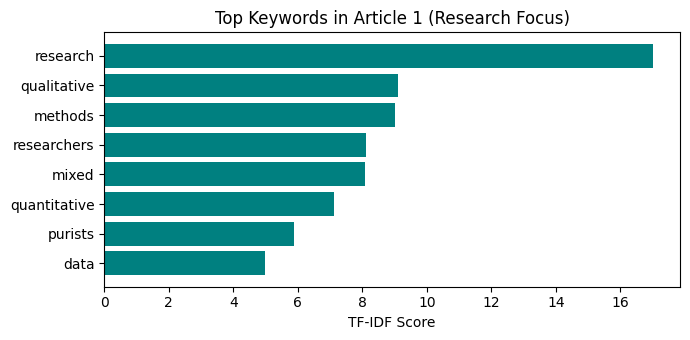

In [ ]:
art1 = df.loc[df['article_id'] == '/content/research_1', 'content'].values[0]
sentences = [s.strip() for s in art1.split('.') if len(s.strip()) > 20]
vec = TfidfVectorizer(stop_words='english')
X_sents = vec.fit_transform(sentences)
scores = np.array(X_sents.sum(axis=1)).flatten()
top_idx = scores.argsort()[-3:][::-1]
summary_art1 = [sentences[i] for i in sorted(top_idx)]

feature_names = vec.get_feature_names_out()
tfidf_sums = np.array(X_sents.sum(axis=0)).flatten()
top_kw = [feature_names[i] for i in tfidf_sums.argsort()[-8:][::-1]]
top_sc = [tfidf_sums[i] for i in tfidf_sums.argsort()[-8:][::-1]]

plt.figure(figsize=(7, 3.5))
plt.barh(top_kw[::-1], top_sc[::-1], color='teal')
plt.xlabel('TF-IDF Score')
plt.title('Top Keywords in Article 1 (Research Focus)')
plt.tight_layout()
plt.show()
plt.close()


3.4 Aggregate Summarization and Incline Visualization

Aggregate Theme 1: development, developmental, mixed, instructional, methods
Aggregate Theme 2: alpha, instrument, cronbachs, reliability, scales
Aggregate Theme 3: triangulation, reflexivity, researcher, researchers, fusch


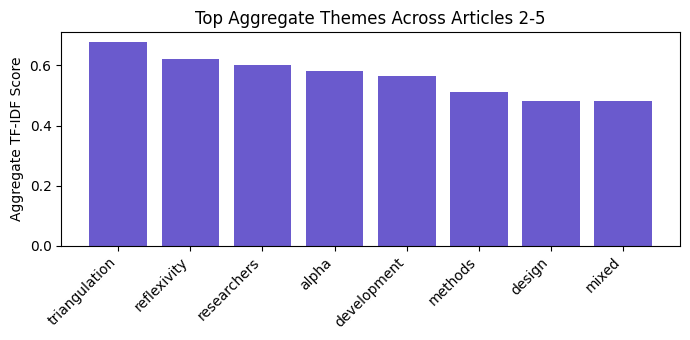

All tasks completed successfully and visualizations generated!


In [ ]:
df_rem = df[df['article_id'] != 'research_1']
agg_vec = TfidfVectorizer(max_df=0.85, min_df=1, stop_words='english')
X_agg = agg_vec.fit_transform(df_rem['cleaned'])
lda = LatentDirichletAllocation(n_components=3, random_state=42)
lda.fit(X_agg)

vocab = agg_vec.get_feature_names_out()
for idx, topic in enumerate(lda.components_):
    words = [vocab[i] for i in topic.argsort()[-5:][::-1]]
    print(f"Aggregate Theme {idx+1}: {', '.join(words)}")

plt.figure(figsize=(7, 3.5))
global_tfidf = np.array(X_agg.sum(axis=0)).flatten()
global_kw_indices = global_tfidf.argsort()[-8:][::-1]
global_keywords = [vocab[i] for i in global_kw_indices]
global_scores = [global_tfidf[i] for i in global_kw_indices]

plt.bar(global_keywords, global_scores, color='slateblue')
plt.xticks(rotation=45, ha='right')
plt.ylabel('Aggregate TF-IDF Score')
plt.title('Top Aggregate Themes Across Articles 2-5')
plt.tight_layout()
plt.show()

print("All tasks completed successfully and visualizations generated!")

## 4. LDA Topic Modelling & Topic Word Distributio and Visualization

Topic 1: development, methods, researchers, mixed, quantitative, developmental, design, instructional
Topic 2: alpha, instrument, science, reliability, cronbachs, items, education, authors
Topic 3: triangulation, researchers, researcher, reflexivity, design, fusch, multiple, methods

Document-Topic Probability Distribution:
               Article   Topic 1   Topic 2   Topic 3
0  /content/research_1  0.999691  0.000154  0.000155
1  /content/research_2  0.000359  0.000354  0.999287
2  /content/research_3  0.999556  0.000225  0.000220
3  /content/research_4  0.000146  0.999710  0.000144
4  /content/research_5  0.000227  0.000224  0.999549


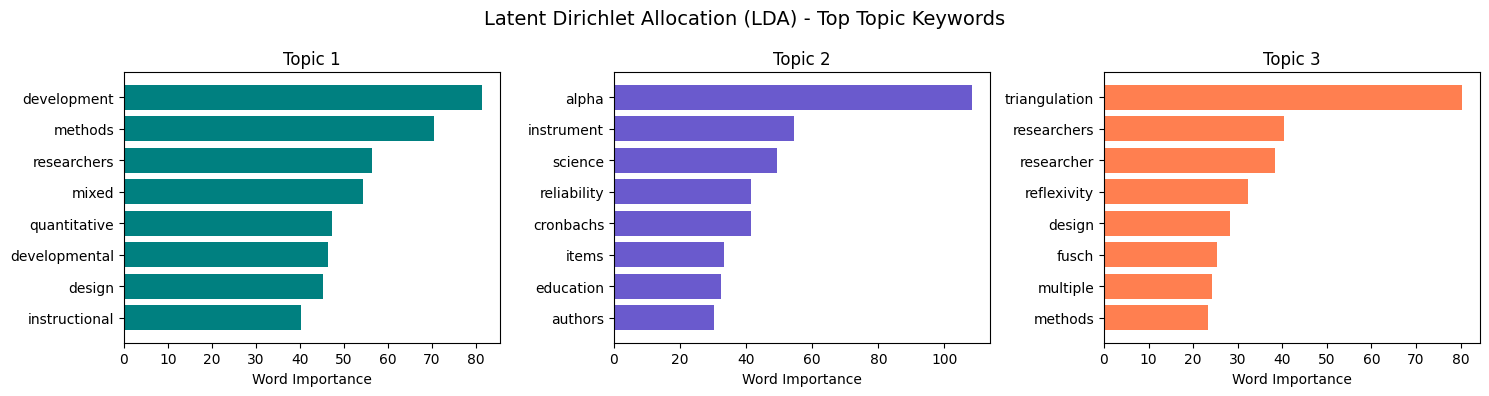

In [ ]:
count_vec = CountVectorizer(max_df=0.85, min_df=1, stop_words='english')
X_counts = count_vec.fit_transform(df['cleaned'])

# Fit LDA model with 3 topics
n_topics = 3
lda = LatentDirichletAllocation(n_components=n_topics, random_state=42)
lda.fit(X_counts)

# Extract and display top words per topic
vocab = count_vec.get_feature_names_out()
for idx, topic in enumerate(lda.components_):
    top_words = [vocab[i] for i in topic.argsort()[-8:][::-1]]
    print(f"Topic {idx + 1}: {', '.join(top_words)}")

# Document-Topic Distribution Matrix
doc_topic_dist = lda.transform(X_counts)
df_doc_topic = pd.DataFrame(doc_topic_dist, columns=[f'Topic {i+1}' for i in range(n_topics)])
df_doc_topic['Article'] = df['article_id']
print("\nDocument-Topic Probability Distribution:")
print(df_doc_topic[['Article', 'Topic 1', 'Topic 2', 'Topic 3']])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=False)
for idx, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-8:][::-1]
    top_words = [vocab[i] for i in top_indices]
    top_scores = [topic[i] for i in top_indices]

    axes[idx].barh(top_words[::-1], top_scores[::-1], color=['teal', 'slateblue', 'coral'][idx])
    axes[idx].set_title(f'Topic {idx + 1}')
    axes[idx].set_xlabel('Word Importance')

plt.suptitle('Latent Dirichlet Allocation (LDA) - Top Topic Keywords', fontsize=14)
plt.tight_layout()
plt.show()

4.2 Intertopic Distance Interactive Map using pyLDAvis

In [ ]:
import pyLDAvis.lda_model
vis_panel = pyLDAvis.lda_model.prepare(lda, X_counts, count_vec, mds='tsne')
pyLDAvis.display(vis_panel)